# ξ(r) from m of k partitions

A catalogue is made of k partitions, each sampling the whole box, and only m
of them are available. This notebook measures ξ(r) from m = 2 of k = 8
partitions of a mock catalogue and compares it with the full box.

In [1]:
from itertools import combinations

import matplotlib.pyplot as plt
import numpy as np
from pysauce import compute_xi

## A mock catalogue

Haloes are placed at random and each is given a few galaxies, so the
catalogue is clustered on the scale of a halo (1 Mpc/h) and unclustered on
large scales. Each halo is assigned to one of the k partitions.

In [2]:
def clustered_mock(n_haloes, mean_members, halo_size, box_size, k, rng):
    """Galaxies scattered around randomly placed haloes.

    Every galaxy of a halo gets that halo's partition label, as when each
    partition holds the galaxies of one file of merger trees.
    """
    centres = rng.uniform(0, box_size, (n_haloes, 3))
    halo = np.repeat(np.arange(n_haloes), rng.poisson(mean_members, n_haloes))
    coords = (centres[halo] + rng.normal(0, halo_size, (len(halo), 3))) % box_size
    coords[coords >= box_size] = 0.0  # the modulo can round up to box_size
    partition_ids = rng.integers(0, k, n_haloes, dtype=np.int32)[halo]
    return coords, partition_ids


BOX_SIZE = 500.0  # Mpc/h
K = 8             # partitions in the full catalogue

rng = np.random.default_rng(1)
coords, partition_ids = clustered_mock(40_000, 5, 1.0, BOX_SIZE, K, rng)
print(f"{len(coords):,} galaxies in {K} partitions")

199,659 galaxies in 8 partitions


## The full box

With every partition present (m = k) the weights are 1 and `compute_xi` is an
ordinary pair count compared with the analytic random counts.

In [3]:
r_bins = np.logspace(-1, np.log10(30.0), 17)

full = compute_xi(
    coords, partition_ids, r_bins, BOX_SIZE, n_partitions=K, n_partitions_selected=K
)
r = full["r_mid"]

## Two partitions of eight

Pass only the galaxies of the selected partitions, and say how many
partitions were selected and how many there are in total.

In [4]:
def select(chosen):
    """The galaxies of the chosen partitions."""
    keep = np.isin(partition_ids, chosen)
    return coords[keep], partition_ids[keep]


M = 2
sparse = compute_xi(
    *select([0, 1]), r_bins, BOX_SIZE, n_partitions=K, n_partitions_selected=M
)

For comparison, the same galaxies treated as if they were a complete
catalogue (k = m, so no correction). Pairs within a halo always share a
partition, so they survive the selection more often than pairs between
partitions, and the uncorrected ξ(r) is too high on small scales by a factor
of about k / m.

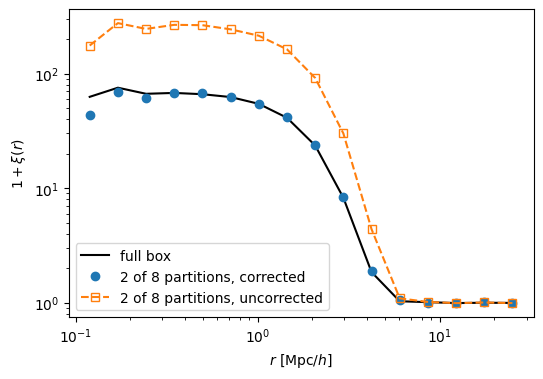

In [5]:
uncorrected = compute_xi(
    *select([0, 1]), r_bins, BOX_SIZE, n_partitions=M, n_partitions_selected=M
)

fig, ax = plt.subplots(figsize=(6, 4))
ax.loglog(r, 1 + full["xi"], "k-", label="full box")
ax.loglog(r, 1 + sparse["xi"], "o", label=f"{M} of {K} partitions, corrected")
ax.loglog(r, 1 + uncorrected["xi"], "s--", mfc="none", label=f"{M} of {K} partitions, uncorrected")
ax.set_xlabel(r"$r$ [Mpc/$h$]")
ax.set_ylabel(r"$1 + \xi(r)$")
ax.legend()
plt.show()

## Every selection

The correction weights the pairs within a partition (`dd_auto`) and the pairs
between partitions (`dd_cross`) by the inverse of the probability that they
survive the selection. Averaged over all 28 ways of choosing 2 partitions
from 8, the corrected counts are therefore the counts of the full box.

`compute_xi` returns the corrected counts at the observed density, so they
are multiplied by (k / m)² to compare them with the full box.

In [6]:
selections = list(combinations(range(K), M))
results = [
    compute_xi(*select(chosen), r_bins, BOX_SIZE, n_partitions=K, n_partitions_selected=M)
    for chosen in selections
]

mean_counts = np.mean([res["dd_corr"] for res in results], axis=0) * (K / M) ** 2
full_counts = full["dd_auto"] + full["dd_cross"]
print("largest relative difference:", np.max(np.abs(mean_counts / full_counts - 1)))

largest relative difference: 0.0


A single selection scatters about the full box. The scatter is largest where
pairs are few.

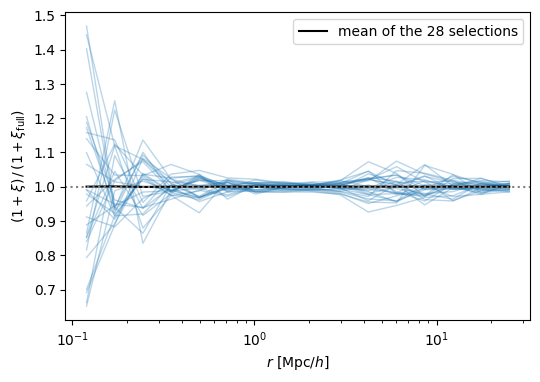

In [7]:
fig, ax = plt.subplots(figsize=(6, 4))
for res in results:
    ax.semilogx(r, (1 + res["xi"]) / (1 + full["xi"]), color="C0", alpha=0.3, lw=1)
mean_xi = np.mean([res["xi"] for res in results], axis=0)
ax.semilogx(r, (1 + mean_xi) / (1 + full["xi"]), "k-", label="mean of the 28 selections")
ax.axhline(1, color="grey", ls=":")
ax.set_xlabel(r"$r$ [Mpc/$h$]")
ax.set_ylabel(r"$(1 + \xi) \,/\, (1 + \xi_{\rm full})$")
ax.legend()
plt.show()